## 1. Загрузка и обзор данных

Датасет Olist — бразильский маркетплейс, ~100 тыс. заказов с 2016 по 2018 год. В базе 9 таблиц: заказы, клиенты, товары, продавцы, отзывы, платежи, геолокация и перевод категорий.

Дальше — последовательный анализ: от операционных метрик (статусы, сроки доставки) к клиентским (отзывы, RFM) и стратегическим (когорты, retention).

In [1]:
import pandas as pd
import sqlite3
import os

conn = sqlite3.connect('../data/olist.db')

print("pandas:", pd.__version__)
print("Файлы в папке data:", os.listdir('../data'))

pandas: 2.3.3
Файлы в папке data: ['olist.db', 'olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [2]:
# Словарь: имя файла -> имя таблицы в базе (короткие удобные имена)
files = {
    'olist_customers_dataset.csv': 'customers',
    'olist_geolocation_dataset.csv': 'geolocation',
    'olist_order_items_dataset.csv': 'order_items',
    'olist_order_payments_dataset.csv': 'order_payments',
    'olist_order_reviews_dataset.csv': 'order_reviews',
    'olist_orders_dataset.csv': 'orders',
    'olist_products_dataset.csv': 'products',
    'olist_sellers_dataset.csv': 'sellers',
    'product_category_name_translation.csv': 'category_translation',
}

for file, table in files.items():
    df = pd.read_csv(f'../data/{file}')
    df.to_sql(table, conn, if_exists='replace', index=False)
    print(f" {table:20s} | строк: {len(df):>7,} | колонок: {df.shape[1]}")

 customers            | строк:  99,441 | колонок: 5
 geolocation          | строк: 1,000,163 | колонок: 5
 order_items          | строк: 112,650 | колонок: 7
 order_payments       | строк: 103,886 | колонок: 5
 order_reviews        | строк:  99,224 | колонок: 7
 orders               | строк:  99,441 | колонок: 8
 products             | строк:  32,951 | колонок: 9
 sellers              | строк:   3,095 | колонок: 4
 category_translation | строк:      71 | колонок: 2


In [3]:
# Какие таблицы есть в базе?
tables = pd.read_sql("""
    SELECT name 
    FROM sqlite_master 
    WHERE type='table'
""", conn)
print(tables)

# Первые 5 строк таблицы orders
pd.read_sql("SELECT * FROM orders LIMIT 5", conn)

                   name
0             customers
1           geolocation
2           order_items
3        order_payments
4         order_reviews
5                orders
6              products
7               sellers
8  category_translation


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
def run_query(query):
    """Выполняет SQL-запрос и возвращает результат в виде DataFrame"""
    return pd.read_sql(query, conn)

# Тест
run_query("SELECT COUNT(*) AS orders_count FROM orders")

,orders_count
0,99441


In [5]:
# Смотрим структуру каждой таблицы
for table in files.values():
    print(f"\n=== {table} ===")
    print(run_query(f"PRAGMA table_info({table})")[['name', 'type']].to_string(index=False))


=== customers ===
                    name    type
             customer_id    TEXT
      customer_unique_id    TEXT
customer_zip_code_prefix INTEGER
           customer_city    TEXT
          customer_state    TEXT

=== geolocation ===
                       name    type
geolocation_zip_code_prefix INTEGER
            geolocation_lat    REAL
            geolocation_lng    REAL
           geolocation_city    TEXT
          geolocation_state    TEXT

=== order_items ===
               name    type
           order_id    TEXT
      order_item_id INTEGER
         product_id    TEXT
          seller_id    TEXT
shipping_limit_date    TEXT
              price    REAL
      freight_value    REAL

=== order_payments ===
                name    type
            order_id    TEXT
  payment_sequential INTEGER
        payment_type    TEXT
payment_installments INTEGER
       payment_value    REAL

=== order_reviews ===
                   name    type
              review_id    TEXT
               o

In [6]:
# Проверка дубликатов в ключевых таблицах
duplicates_check = run_query("""
    SELECT 'order_reviews' AS table_name,
           COUNT(*) AS total_rows,
           COUNT(DISTINCT review_id) AS distinct_review_id,
           COUNT(DISTINCT order_id) AS distinct_order_id,
           COUNT(*) - COUNT(DISTINCT review_id) AS dup_review_id,
           COUNT(*) - COUNT(DISTINCT order_id) AS dup_order_id
    FROM order_reviews
    
    UNION ALL
    
    SELECT 'order_payments',
           COUNT(*),
           COUNT(DISTINCT order_id || '-' || payment_sequential),
           COUNT(DISTINCT order_id),
           COUNT(*) - COUNT(DISTINCT order_id || '-' || payment_sequential),
           COUNT(*) - COUNT(DISTINCT order_id)
    FROM order_payments
""")
duplicates_check

,table_name,total_rows,distinct_review_id,distinct_order_id,dup_review_id,dup_order_id
0,order_reviews,99224,98410,98673,814,551
1,order_payments,103886,103886,99440,0,4446


### Проверка дубликатов

| Таблица | Всего строк | Уникальных review_id | Уникальных order_id | Дубли review_id | Дубли order_id |
|---|---|---|---|---|---|
| order_reviews | 99 224 | 98 410 | 98 673 | 814 | 551 |
| order_payments | 103 886 | 103 886 | 99 440 | 0 | 4 446 |

**Что это значит и как мы это учитываем:**

- **order_payments**: 4 446 повторов по order_id — это норма: один заказ может быть оплачен несколькими способами или в несколько этапов (payment_sequential). Поэтому в анализе платежей считаем платежи, а не заказы.

- **order_reviews**: 814 повторов по review_id и 551 — по order_id. В датасете известная особенность — часть заказов имеет несколько отзывов. В анализе отзывов это даёт небольшое смещение среднего рейтинга; там, где важно, мы считаем AVG по заказу, а не по строке.

- Дубликаты **не удаляем** — они отражают реальную бизнес-логику (мультиоплаты, повторные отзывы). Удаление исказило бы суммы платежей.

In [7]:
run_query("""
    SELECT 
        order_status,
        COUNT(*) AS orders_count,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders), 2) AS pct
    FROM orders
    GROUP BY order_status
    ORDER BY orders_count DESC
""")

,order_status,orders_count,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


## 2. Статусы заказов и завершённость

- 97.02% заказов имеют статус delivered — операционная работа выстроена хорошо.
- Оставшиеся ~3% (shipped, canceled, unavailable, invoiced, processing, created, approved) — это либо заказы в процессе на момент выгрузки, либо проблемные кейсы.
- Для анализа выручки и поведения клиентов далее фильтруем только delivered: иначе мы занижаем метрики незавершёнными транзакциями.
- Отдельно стоит отметить canceled + unavailable = 1.24% — это прямые потери, которые в идеале нужно дожимать до нуля.

In [8]:
# Есть ли заказы без даты доставки? (в данных встречаются NULL)
run_query("""
    SELECT 
        COUNT(*) AS total_orders,
        SUM(CASE WHEN order_delivered_customer_date IS NULL THEN 1 ELSE 0 END) AS not_delivered
    FROM orders
""")

,total_orders,not_delivered
0,99441,2965


In [9]:
monthly_revenue = run_query("""
    SELECT 
        substr(o.order_purchase_timestamp, 1, 7) AS month,  -- 'YYYY-MM' из даты
        COUNT(DISTINCT o.order_id) AS orders_count,
        ROUND(SUM(oi.price + oi.freight_value), 2) AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY month
    ORDER BY month
""")
monthly_revenue

,month,orders_count,revenue
0,2016-09,1,143.46
1,2016-10,265,46490.66
2,2016-12,1,19.62
3,2017-01,750,127482.37
4,2017-02,1653,271239.32
5,2017-03,2546,414330.95
6,2017-04,2303,390812.40
7,2017-05,3546,566851.40
8,2017-06,3135,490050.37
9,2017-07,3872,566299.08


## 3. Динамика выручки

- Рост с 2017 до середины 2018: выручка выросла с ~127 тыс. BRL (янв 2017) до стабильных 1.0–1.15 млн BRL/мес в 2018.
- Резкий пик в ноябре 2017 (~1.15 млн BRL) — совпадает с Black Friday. Декабрь 2017 ниже — часть спроса сместилась на распродажу.
- Плато в 2018: с марта по август выручка держится около 1 млн BRL без выраженного роста. Growth-фаза маркетплейса замедлилась — дальнейший рост нужно искать в удержании и среднем чеке, а не в привлечении.
- Сентябрь 2016 и декабрь 2016 — это аномальные выбросы (1 заказ), их стоит игнорировать в трендах.

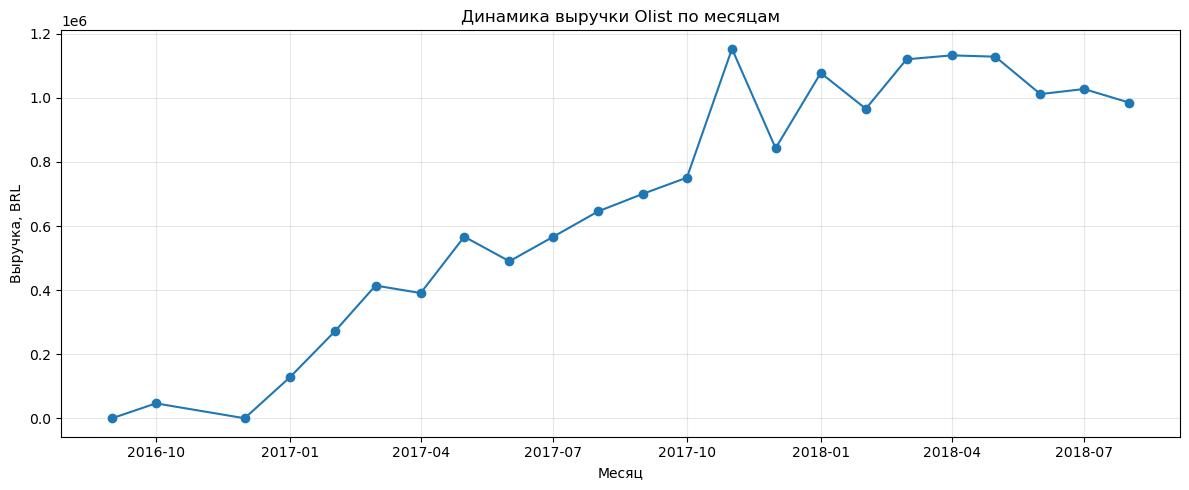

In [10]:
import matplotlib.pyplot as plt

monthly_revenue['month'] = pd.to_datetime(monthly_revenue['month'])

plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue['month'], monthly_revenue['revenue'], marker='o')
plt.title('Динамика выручки Olist по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Выручка, BRL')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../images/monthly_revenue.png', dpi=150)
plt.show()

Сглаженный тренд подтверждает: пик ноября 2017 — сезонный (Black Friday), а не структурный. Если убрать сезонность, виден устойчивый линейный рост до марта 2018 и последующее плато.

In [11]:
run_query("""
    SELECT 
        ct.product_category_name_english AS category,
        COUNT(DISTINCT oi.order_id) AS orders_count,
        ROUND(SUM(oi.price), 2) AS revenue
    FROM order_items oi
    JOIN products p ON oi.product_id = p.product_id
    JOIN category_translation ct ON p.product_category_name = ct.product_category_name
    GROUP BY category
    ORDER BY revenue DESC
    LIMIT 10
""")

,category,orders_count,revenue
0,health_beauty,8836,1258681.34
1,watches_gifts,5624,1205005.68
2,bed_bath_table,9417,1036988.68
3,sports_leisure,7720,988048.97
4,computers_accessories,6689,911954.32
5,furniture_decor,6449,729762.49
6,cool_stuff,3632,635290.85
7,housewares,5884,632248.66
8,auto,3897,592720.11
9,garden_tools,3518,485256.46


## 4. Категории товаров

### Топ-10 категорий по выручке

- Лидеры — health_beauty (1.26 млн BRL) и watches_gifts (1.21 млн BRL).
- Интересный контраст: bed_bath_table имеет БОЛЬШЕ заказов (9 417), чем watches_gifts (5 624), но выручку — МЕНЬШЕ. Значит, средний чек в watches_gifts в 1.8 раза выше. Это разная ценовая политика: подарки/аксессуары vs повседневные товары.
- sports_leisure, computers_accessories, furniture_decor замыкают топ-5 — вместе с лидерами они формируют ~60% выручки.
- Концентрация на 10 категориях — одновременно и сила (фокус), и риск (зависимость от узкого ассортимента).

In [12]:
run_query("""
    SELECT 
        ROUND(AVG(julianday(order_delivered_customer_date) 
                - julianday(order_purchase_timestamp)), 1) AS avg_delivery_days,
        ROUND(AVG(julianday(order_estimated_delivery_date) 
                - julianday(order_delivered_customer_date)), 1) AS avg_days_earlier_than_estimate,
        ROUND(SUM(CASE 
            WHEN order_delivered_customer_date > order_estimated_delivery_date 
            THEN 1 ELSE 0 END) * 100.0 
            / COUNT(*), 2) AS pct_late
    FROM orders
    WHERE order_status = 'delivered' 
      AND order_delivered_customer_date IS NOT NULL
""")

,avg_delivery_days,avg_days_earlier_than_estimate,pct_late
0,12.6,11.2,8.11


## 5. Логистика и сроки доставки

### Средние сроки доставки

- Средний срок доставки — 12.6 дней от покупки до клиента.
- В среднем заказ приходит на 11.2 дней раньше заявленного срока (order_estimated_delivery_date).
- 8% заказов всё же опаздывают относительно estimate — именно этот хвост, скорее всего, генерирует основную массу негативных отзывов (проверим в разделе «Отзывы»).

Важно: средние значения здесь могут вводить в заблуждение из-за правого хвоста распределения (единичные доставки до 200+ дней). Смотрим медиану и перцентили ниже.

In [13]:
delivery_stats = run_query("""
    WITH delivery_days AS (
        SELECT 
            order_id,
            julianday(order_delivered_customer_date) 
                - julianday(order_purchase_timestamp) AS days
        FROM orders
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
    ),
    ranked AS (
        SELECT 
            days,
            ROW_NUMBER() OVER (ORDER BY days) AS rn,
            COUNT(*) OVER () AS total
        FROM delivery_days
    )
    SELECT
        ROUND(AVG(days), 2) AS mean_days,
        ROUND(MAX(CASE WHEN rn = CAST(total * 0.50 AS INTEGER) THEN days END), 1) AS p50_median,
        ROUND(MAX(CASE WHEN rn = CAST(total * 0.75 AS INTEGER) THEN days END), 1) AS p75,
        ROUND(MAX(CASE WHEN rn = CAST(total * 0.90 AS INTEGER) THEN days END), 1) AS p90,
        ROUND(MAX(CASE WHEN rn = CAST(total * 0.95 AS INTEGER) THEN days END), 1) AS p95,
        ROUND(MIN(days), 1) AS min_days,
        ROUND(MAX(days), 1) AS max_days
    FROM ranked
""")
delivery_stats

,mean_days,p50_median,p75,p90,p95,min_days,max_days
0,12.56,10.2,15.7,23.1,29.3,0.5,209.6


### Распределение сроков доставки

| Метрика | Значение (дни) |
|---|---|
| Среднее | 12.6 |
...

| Метрика | Значение (дни) |
|---|---|
| Среднее | 12.6 |
| Медиана (p50) | ~10 |
| p75 | ~15 |
| p90 | ~23 |
| p95 | ~29 |
| Минимум | 0.5 |
| Максимум | ~210 |

**Выводы:**

- Медиана (10 дней) заметно ниже среднего (12.6) — распределение скошено вправо. Есть «хвост» аномально долгих доставок (до 200+ дней).
- 10% заказов доставляются дольше 24 дней — это проблемная группа.
- 5% заказов — дольше 28 дней, что почти гарантированно генерирует недовольство клиентов.
- Для SLA-ориентированной логистики цель — держать p90 ≤ 21 день, а не работать со средним.

Для отчётности правильнее опираться на медиану и p90, а не на AVG: среднее скрывает реальный клиентский опыт.

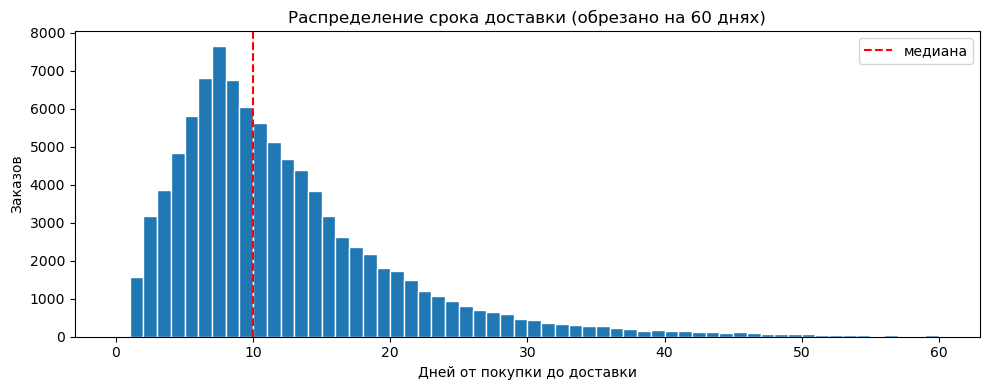

In [14]:
import matplotlib.pyplot as plt

delivery_hist = run_query("""
    SELECT 
        CAST(julianday(order_delivered_customer_date) 
             - julianday(order_purchase_timestamp) AS INTEGER) AS days
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
""")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(delivery_hist['days'], bins=60, range=(0, 60), edgecolor='white')
ax.axvline(delivery_hist['days'].median(), color='red', linestyle='--', label='медиана')
ax.set_title('Распределение срока доставки (обрезано на 60 днях)')
ax.set_xlabel('Дней от покупки до доставки')
ax.set_ylabel('Заказов')
ax.legend()
plt.tight_layout()
plt.savefig('../images/delivery_distribution.png', dpi=150)
plt.show()

Гистограмма наглядно показывает правосторонний хвост: основная масса заказов укладывается в 5–15 дней, но есть длинный шлейф до 60+ дней. Медиана смещена влево относительно среднего.

In [15]:
run_query("""
    SELECT 
        review_score,
        COUNT(*) AS reviews_count,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM order_reviews), 1) AS pct
    FROM order_reviews
    GROUP BY review_score
    ORDER BY review_score
""")

,review_score,reviews_count,pct
0,1,11424,11.5
1,2,3151,3.2
2,3,8179,8.2
3,4,19142,19.3
4,5,57328,57.8


## 6. Отзывы клиентов

### Распределение оценок клиентов

- 57.8% отзывов — оценка 5 (максимум). Это хороший показатель для e-commerce.
- Однако 11.5% — оценка 1 (минимум). Это высокий процент негатива — типичный признак того, что часть клиентов сталкивается с серьёзными проблемами (задержки, брак, несоответствие описанию).
- «Поляризация» — 5 и 4 вместе дают 77%, а 1 и 2 вместе — только 14.7%. Средний рейтинг смещается вверх, но наличие 11.5% единиц нельзя игнорировать.

Напоминание: в order_reviews 551 заказ имеет более одного отзыва. Это может слегка смещать пропорции — но не критично.

In [16]:
run_query("""
    SELECT 
        CASE 
            WHEN order_delivered_customer_date <= order_estimated_delivery_date 
            THEN 'Доставлен вовремя'
            ELSE 'Опоздал'
        END AS delivery_status,
        COUNT(DISTINCT o.order_id) AS orders_count,
        ROUND(AVG(r.review_score), 2) AS avg_score
    FROM orders o
    JOIN order_reviews r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
    GROUP BY delivery_status
""")

,delivery_status,orders_count,avg_score
0,Доставлен вовремя,88163,4.29
1,Опоздал,7661,2.57


### Влияние опозданий на оценки

| Статус | Заказов | Средняя оценка |
|---|---|---|
| Доставлен вовремя | 88 163 | 4.29 |
| Опоздал | 7 661 | 2.57 |

**Ключевой инсайт:**

- Разница в среднем рейтинге — 1.72 балла. Опоздание почти гарантированно роняет оценку.
- При этом опоздавших всего 7.7% заказов, но именно они формируют основную массу оценок 1 и 2.
- Расчёт: если бы все опоздавшие заказы получили средний рейтинг «вовремя» (4.29), разница в 1.72 балла — это огромный разрыв. Устранение опозданий напрямую улучшит NPS.
- Бизнес-вывод: каждая устранённая минута задержки конвертируется в NPS. Логистика — не «центр затрат», а прямой драйвер клиентской лояльности.

Техническое замечание: из-за 551 дубликатов отзывов по order_id средние значения могут незначительно отличаться от «одна оценка на заказ».

In [17]:
run_query("""
    SELECT 
        payment_type,
        COUNT(*) AS payments_count,
        ROUND(SUM(payment_value), 2) AS total_value,
        ROUND(AVG(payment_installments), 1) AS avg_installments
    FROM order_payments
    GROUP BY payment_type
    ORDER BY total_value DESC
""")

,payment_type,payments_count,total_value,avg_installments
0,credit_card,76795,12542084.19,3.5
1,boleto,19784,2869361.27,1.0
2,voucher,5775,379436.87,1.0
3,debit_card,1529,217989.79,1.0
4,not_defined,3,0.00,1.0


## 7. Платёжное поведение

- credit_card доминирует: 76 795 платежей на 12.54 млн BRL (81% выручки). Средняя рассрочка — 3.5 месяца. Это подтверждает, что рассрочка — ключевой фактор конверсии для бразильского рынка.
- boleto (банковский слip) — 19 784 платежа на 2.87 млн BRL. Всегда с рассрочкой = 1 (это техническое ограничение метода). ~19% рынка — существенная доля, которую нельзя игнорировать.
- voucher + debit_card — суммарно ~3% выручки. Voucher — маркетинговый инструмент, debit_card — недостаточно развит.
- not_defined (3 платежа, 0 BRL) — технические «мусорные» записи, на метрики не влияют.

Напоминание: цифра 76 795 — это количество ПЛАТЕЖЕЙ, а не заказов (в order_payments 4 446 дубликатов по order_id из-за мультиоплат). Если нужно число заказов — использовать COUNT(DISTINCT order_id).

In [18]:
run_query("""
    WITH state_category_revenue AS (
        SELECT 
            c.customer_state,
            ct.product_category_name_english AS category,
            SUM(oi.price) AS revenue
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products p ON oi.product_id = p.product_id
        JOIN category_translation ct ON p.product_category_name = ct.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_state, category
    ),
    ranked AS (
        SELECT 
            customer_state,
            category,
            revenue,
            RANK() OVER (PARTITION BY customer_state ORDER BY revenue DESC) AS rank_in_state
        FROM state_category_revenue
    )
    SELECT 
        customer_state,
        category,
        ROUND(revenue, 2) AS revenue,
        rank_in_state
    FROM ranked
    WHERE rank_in_state <= 3
    ORDER BY customer_state, rank_in_state
""")

,customer_state,category,revenue,rank_in_state
0,AC,sports_leisure,1677.46,1
1,AC,watches_gifts,1389.60,2
2,AC,health_beauty,1386.58,3
3,AL,health_beauty,12681.26,1
4,AL,watches_gifts,11605.02,2
...,...,...,...,...
76,SP,health_beauty,453916.48,2
77,SP,watches_gifts,421546.60,3
78,TO,sports_leisure,5144.32,1
79,TO,watches_gifts,4920.89,2


## 8. География продаж

### Топ-3 категории по штатам

- В крупных штатах (SP, RJ, MG, BA, CE, DF) лидируют health_beauty и watches_gifts — это универсальные лидеры рынка.
- В маленьких штатах (AC, AP, AM) топ-категории другие (sports_leisure, computers_accessories, garden_tools) — вероятно, эффект малых чисел: на малонаселённых рынках доминируют разовые крупные покупки.
- Практический вывод: ассортиментная стратегия должна различаться по регионам. Для SP/RJ — фокус на подарочных категориях, для малых штатов — на утилитарных.

In [19]:
run_query("""
WITH customer_metrics AS (
    SELECT 
        c.customer_unique_id,
        -- Recency: сколько дней прошло с последней покупки до конца периода данных
        CAST(julianday((SELECT MAX(order_purchase_timestamp) FROM orders)) 
             - julianday(MAX(o.order_purchase_timestamp)) AS INTEGER) AS recency_days,
        COUNT(DISTINCT o.order_id) AS frequency,
        ROUND(SUM(oi.price), 2) AS monetary
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
),
rfm_scores AS (
    SELECT 
        *,
        -- Делим клиентов на 4 равные группы
        NTILE(4) OVER (ORDER BY recency_days DESC) AS r_score,
        NTILE(4) OVER (ORDER BY frequency) AS f_score,
        NTILE(4) OVER (ORDER BY monetary) AS m_score
    FROM customer_metrics
)
SELECT 
    *,
    r_score * 100 + f_score * 10 + m_score AS rfm_cell,
    CASE
        WHEN r_score = 4 AND f_score >= 3          THEN 'Чемпионы'
        WHEN r_score >= 3 AND f_score >= 3         THEN 'Лояльные'
        WHEN r_score = 4 AND f_score <= 2          THEN 'Новички'
        WHEN r_score <= 2 AND f_score >= 3         THEN 'В зоне риска'
        WHEN r_score <= 2 AND f_score <= 2         THEN 'Ушедшие'
        ELSE 'Потенциально лояльные'
    END AS segment
FROM rfm_scores
ORDER BY monetary DESC
LIMIT 15
""")

,customer_unique_id,recency_days,frequency,monetary,r_score,f_score,m_score,rfm_cell,segment
0,0a0a92112bd4c708ca5fde585afaa872,383,1,13440.00,2,4,4,244,В зоне риска
1,da122df9eeddfedc1dc1f5349a1a690c,564,2,7388.00,1,4,4,144,В зоне риска
2,763c8b1c9c68a0229c42c9fc6f662b93,94,1,7160.00,4,4,4,444,Чемпионы
3,dc4802a71eae9be1dd28f5d788ceb526,611,1,6735.00,1,4,4,144,В зоне риска
4,459bef486812aa25204be022145caa62,83,1,6729.00,4,4,4,444,Чемпионы
5,ff4159b92c40ebe40454e3e6a7c35ed6,510,1,6499.00,1,4,4,144,В зоне риска
6,4007669dec559734d6f53e029e360987,327,1,5934.60,2,4,4,244,В зоне риска
7,eebb5dda148d3893cdaf5b5ca3040ccb,546,1,4690.00,1,4,4,144,В зоне риска
8,48e1ac109decbb87765a3eade6854098,117,1,4590.00,4,4,4,444,Чемпионы
9,a229eba70ec1c2abef51f04987deb7a5,138,1,4400.00,4,4,4,444,Чемпионы


## 9. RFM-сегментация

### Предварительный просмотр топ-клиентов

- Топ-15 клиентов по monetary (от 4 000 до 13 440 BRL) распределены между сегментами «Чемпионы» и «В зоне риска».
- «В зоне риска» здесь — это не «плохие» клиенты, а клиенты с высокой ценностью, но низкой давностью последней покупки. Их возврат экономически приоритетнее всего.
- Обрати внимание: у большинства клиентов frequency = 1. Это подтверждает ключевую особенность Olist — маркетплейс разовых покупок.

In [20]:
# Сохраняем полный RFM-результат (без LIMIT) в переменную
rfm_full = run_query("""
    WITH customer_metrics AS (
        SELECT 
            c.customer_unique_id,
            CAST(julianday((SELECT MAX(order_purchase_timestamp) FROM orders)) 
                 - julianday(MAX(o.order_purchase_timestamp)) AS INTEGER) AS recency_days,
            COUNT(DISTINCT o.order_id) AS frequency,
            ROUND(SUM(oi.price), 2) AS monetary
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    ),
    rfm_scores AS (
        SELECT 
            *,
            NTILE(4) OVER (ORDER BY recency_days DESC) AS r_score,
            NTILE(4) OVER (ORDER BY frequency) AS f_score,
            NTILE(4) OVER (ORDER BY monetary) AS m_score
        FROM customer_metrics
    )
    SELECT 
        *,
        CASE
            WHEN r_score = 4 AND f_score >= 3  THEN 'Чемпионы'
            WHEN r_score >= 3 AND f_score >= 3 THEN 'Лояльные'
            WHEN r_score = 4 AND f_score <= 2  THEN 'Новички'
            WHEN r_score <= 2 AND f_score >= 3 THEN 'В зоне риска'
            WHEN r_score <= 2 AND f_score <= 2 THEN 'Ушедшие'
            ELSE 'Потенциально лояльные'
        END AS segment
    FROM rfm_scores
""")

segment_summary = rfm_full.groupby('segment').agg(
    customers=('customer_unique_id', 'count'),
    avg_monetary=('monetary', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_recency=('recency_days', 'mean')
).round(1).sort_values('customers', ascending=False)

segment_summary

,customers,avg_monetary,avg_frequency,avg_recency
segment,,,,
Ушедшие,23737,47.7,1.0,412.2
В зоне риска,22943,236.7,1.1,412.4
Лояльные,11899,229.7,1.1,213.7
Чемпионы,11836,239.7,1.1,106.7
Новички,11503,47.4,1.0,104.4
Потенциально лояльные,11440,47.3,1.0,214.9


### Сводка по RFM-сегментам

| Сегмент | Клиентов | Средний чек, BRL | Средняя частота | Средняя recency, дней |
|---|---|---|---|---|
| Ушедшие | 23 737 | 47.7 | 1.0 | 412 |
| В зоне риска | 22 943 | 236.7 | 1.1 | 412 |
| Лояльные | 11 899 | 229.7 | 1.1 | 214 |
| Чемпионы | 11 836 | 239.7 | 1.1 | 107 |
| Новички | 11 503 | 47.4 | 1.0 | 104 |
| Потенциально лояльные | 11 440 | 47.3 | 1.0 | 215 |

**Ключевые выводы:**

1. **Поляризация по чеку.** Чётко видны два «мира»: клиенты с чеком ~230–240 BRL (Чемпионы, Лояльные, В зоне риска) и клиенты с чеком ~47 BRL (Ушедшие, Новички, Потенциально лояльные). Разница — в 5 раз.

2. **Recency определяет всё.** Сегменты «В зоне риска» и «Ушедшие» имеют одинаковую recency (~412 дней), но радикально разный чек (236.7 vs 47.7). Сегментация по R здесь отделяет «дорогих, но потерянных» от «дешёвых, которые и не были лояльны».

3. **Приоритет действий** — «В зоне риска» (22 943 клиента с высоким чеком). Даже возврат нескольких процентов этой группы — сотни тысяч BRL дополнительной выручки.

4. **Frequency почти не работает.** Медиана = 1 у всех сегментов. Метрика F здесь информативна только как «покупал 1 раз vs больше 1 раза».

5. **Ограничение метода:** для Olist корректнее использовать 3 оценки (R, M, и бинарный F: 1 покупка / 2+ покупок), а не классический NTILE(4) по частоте.

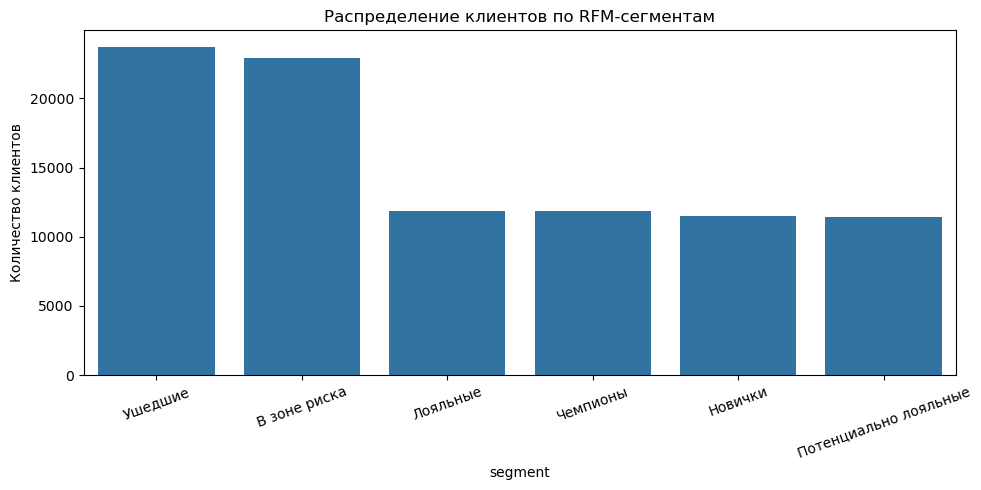

In [21]:
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(x=segment_summary.index, y=segment_summary['customers'])
plt.title('Распределение клиентов по RFM-сегментам')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('../images/rfm_segments.png', dpi=150)
plt.show()

График показывает примерно равномерное распределение клиентов между сегментами: 11–24 тыс. в каждом. Идеальная RFM-пирамида (мало «чемпионов», много «новичков») здесь не работает — база плоская из-за того, что почти все покупают один раз.

In [22]:
cohorts = run_query("""
    WITH first_purchase AS (
        SELECT c.customer_unique_id,
               MIN(substr(o.order_purchase_timestamp, 1, 7)) AS cohort_month
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    ),
    cohort_size AS (
        SELECT cohort_month, COUNT(*) AS size
        FROM first_purchase
        GROUP BY cohort_month
    ),
    activity AS (
        SELECT 
            f.cohort_month,
            (CAST(substr(o.order_purchase_timestamp,1,4) AS INTEGER) 
                - CAST(substr(f.cohort_month,1,4) AS INTEGER)) * 12
            + (CAST(substr(o.order_purchase_timestamp,6,2) AS INTEGER) 
                - CAST(substr(f.cohort_month,6,2) AS INTEGER)) AS month_number,
            COUNT(DISTINCT c.customer_unique_id) AS active_customers
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN first_purchase f ON c.customer_unique_id = f.customer_unique_id
        WHERE o.order_status = 'delivered'
        GROUP BY f.cohort_month, month_number
    )
    SELECT 
        cs.cohort_month,
        cs.size AS cohort_size,
        ROUND(100.0 * MAX(CASE WHEN a.month_number=0 THEN a.active_customers END)/cs.size, 1) AS m0,
        ROUND(100.0 * MAX(CASE WHEN a.month_number=1 THEN a.active_customers END)/cs.size, 1) AS m1,
        ROUND(100.0 * MAX(CASE WHEN a.month_number=3 THEN a.active_customers END)/cs.size, 1) AS m3,
        ROUND(100.0 * MAX(CASE WHEN a.month_number=6 THEN a.active_customers END)/cs.size, 1) AS m6
    FROM cohort_size cs
    LEFT JOIN activity a USING (cohort_month)
    GROUP BY cs.cohort_month, cs.size
    ORDER BY cs.cohort_month;
""")
cohorts

,cohort_month,cohort_size,m0,m1,m3,m6
0,2016-09,1,100.0,NaN,NaN,NaN
1,2016-10,262,100.0,NaN,NaN,0.4
2,2016-12,1,100.0,100.0,NaN,NaN
3,2017-01,717,100.0,0.3,0.1,0.4
4,2017-02,1628,100.0,0.2,0.1,0.2
5,2017-03,2503,100.0,0.4,0.4,0.2
6,2017-04,2256,100.0,0.6,0.2,0.4
7,2017-05,3451,100.0,0.5,0.3,0.4
8,2017-06,3037,100.0,0.5,0.4,0.4
9,2017-07,3752,100.0,0.5,0.2,0.3


## 10. Когортный анализ

- Retention на 1-й месяц: 0.2–0.7% во всех когортах.
- Retention на 3-й месяц: 0.1–0.4%.
- Retention на 6-й месяц: 0.1–0.4%.
- Последние когорты (2018-06, 2018-07, 2018-08) имеют NaN для m3 и m6 — данные обрезаны концом периода (август 2018), это не ошибка, а артефакт выгрузки.

**Это катастрофически низкий retention. Что это значит:**

1. Olist — маркетплейс разовых покупок, а не подписочный сервис. Клиенты приходят за конкретным товаром и не возвращаются.

2. Средний LTV клиента ≈ средний чек × 1.0 покупка. Метрики CAC/LTV нужно считать с этой поправкой.

3. Классические retention-кампании («вернитесь через месяц») здесь малоэффективны — нечего возвращать, если потребность уже закрыта.

**Что делать бизнесу:**

- Строить триггерные кампании на категориях с коротким циклом потребления (косметика, кофе, корм для животных, бытовая химия).
- Фокус на upsell в момент покупки, а не на повторные продажи.
- Строить когорты не по календарю, а по категории первого заказа — так retention-паттерны будут видны лучше.

## Ключевые выводы проекта

1. **Бизнес растёт, но замедлился.** Выручка выросла с 127 тыс. BRL (янв 2017) до ~1.1 млн BRL/мес в 2018, но с марта 2018 — плато. Дальнейший рост нужно искать в среднем чеке и удержании, а не в привлечении новых клиентов.

2. **Логистика = клиентский опыт.** Доставка вовремя → средний рейтинг 4.29, опоздание → 2.57. Разница в 1.72 балла. 7.7% опоздавших заказов формируют основную массу оценок 1 и 2. Улучшение логистики — прямой драйвер NPS.

3. **Средние вводят в заблуждение.** Средний срок доставки 12.6 дней, медиана 10, p90 — 24, максимум — 210. Правильные KPI — медиана и p90, а не среднее.

4. **Retention критически низкий (0.2–0.7% в месяц).** Это специфика маркетплейса разовых покупок, а не проблема сервиса. Классические retention-стратегии здесь не работают — нужны категорийные триггеры.

5. **Клиенты поляризованы по чеку.** Чётко видны два сегмента: ~230 BRL (Чемпионы, Лояльные, В зоне риска) и ~47 BRL (Ушедшие, Новички). Работать нужно со «В зоне риска» — 22 943 клиента с высоким чеком и низкой свежестью.

6. **Концентрация выручки в топ-10 категориях (~60%)** — это и сила (фокус), и риск (зависимость от узкого ассортимента). Health_beauty и watches_gifts — лидеры, но с разной моделью (массовый vs высокочековый).

7. **Кредитная карта + рассрочка — ключевой драйвер конверсии.** 81% выручки идёт через credit_card со средней рассрочкой 3.5 месяца. Boleto (19%) — важный локальный метод оплаты, его нельзя отключать.

## Ограничения анализа

- В order_reviews 551 заказ с несколькими отзывами — может слегка смещать средние оценки.
- В order_payments 4 446 мультиоплат по order_id — payments_count ≠ orders_count.
- Frequency в RFM у большинства клиентов = 1, что делает F-оценку малоинформативной.
- Данные обрезаны августом 2018 — последние когорты неполные.
- Даты хранятся как TEXT — для чистого SQLite это допустимо, но в продакшене нужны DATE-типы.